# 09 – Model Selection and Interpretation

Predicts whether a hexagon has a bubble tea shop from location fundamentals.
The predicted probability serves as a **location suitability score**.

**Validation:** spatial 5-fold cross-validation. Hexagons are grouped into 25 blocks
by their H3 resolution-6 parent (~36 km²) and held out together with
`StratifiedGroupKFold`. All models use the same folds.

**Random vs. spatial split (LightGBM):** AUC 0.858 vs. 0.851. The small gap shows
the features generalize to unseen areas rather than memorizing location.

**Model comparison (spatial CV)**
| Model | ROC AUC | Avg precision | Folds beating logistic |
|---|---|---|---|
| **Logistic regression** | **0.894 ± 0.025** | **0.584 ± 0.126** | — |
| Logistic + splines | 0.887 ± 0.034 | 0.570 ± 0.116 | 2 |
| Random forest | 0.878 ± 0.025 | 0.514 ± 0.103 | 1 |
| LightGBM, regularized + monotone | 0.878 ± 0.031 | 0.537 ± 0.129 | 1 |
| LightGBM | 0.851 ± 0.028 | 0.476 ± 0.120 | 0 |

**Final model: logistic regression** (median imputation → log1p → standardization).
No alternative beat it in more than 2 of 5 folds, so the simplest and most
explainable model was chosen. With only 94 positive hexagons, flexible models
overfit. Regularizing LightGBM raised its AUC from 0.851 to 0.878, confirming this.

**What drives suitability (odds multiplier per 1 SD of the log feature)**
- Food & drink places within 500 m: **5.29×**
- Share aged 15–34: 1.22×
- Median household income: **0.69×** (shops favour less affluent, busier areas)
- Other features are near 1.0 once these are known, as they're correlated with
  commercial activity.

**Ablation:** without food places, spatial AUC is 0.773 ± 0.070 (avg precision
0.428, about 3.9× random). Demographic and location features carry independent
signal; commercial activity improves accuracy and consistency.

**Exploratory (LightGBM SHAP):** distance to station has a non-linear effect.
Very close helps, mid-range hurts, and far away helps again, likely reflecting
car-oriented suburban plazas in Scarborough and North York.

**Figures:** `cv_comparison.png`, `model_comparison.png`, `logit_coefficients.png`,
`shap_importance.png`, `shap_dependence.png`

In [3]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import h3
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

gdf = gpd.read_file("../data/processed/model_features.gpkg")

FEATURES = [
    "dist_station_m", "dist_campus_m", "high_schools_1km", "food_places_500m",
    "catchment_15_34", "median_hh_income", "share_15_34", "pop_density",
]
X = gdf[FEATURES]
y = gdf["has_bubble_tea"]
print("Hexagons:", len(X), "| Share with a shop:", round(y.mean(), 3))

Hexagons: 846 | Share with a shop: 0.111


Spatial blocks: 25


Text(0.5, 1.0, 'Spatial blocks used for cross-validation')

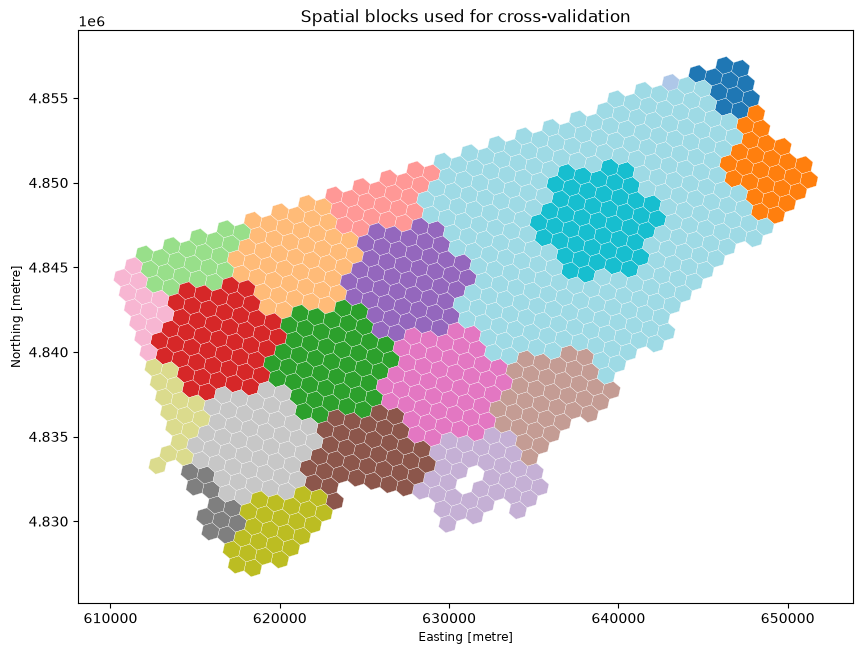

In [4]:
gdf["block"] = gdf["h3_id"].apply(lambda c: h3.cell_to_parent(c, 6))
print("Spatial blocks:", gdf["block"].nunique())

gdf.plot(column="block", categorical=True, cmap="tab20", figsize=(10, 10),
         edgecolor="white", linewidth=0.2)
plt.title("Spatial blocks used for cross-validation")

In [18]:
PARAMS = dict(
    n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=20,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    random_state=42, verbose=-1,
)

def make_lgbm():
    return LGBMClassifier(**PARAMS)

def evaluate(cv, groups=None, make_model=make_lgbm):
    """Train and test on each fold; return out-of-fold predictions and fold scores."""
    oof = np.zeros(len(y))
    aucs, aps = [], []
    for train_idx, test_idx in cv.split(X, y, groups):
        model = make_model()
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        p = model.predict_proba(X.iloc[test_idx])[:, 1]
        oof[test_idx] = p
        aucs.append(roc_auc_score(y.iloc[test_idx], p))
        aps.append(average_precision_score(y.iloc[test_idx], p))
    return oof, np.array(aucs), np.array(aps)

In [19]:
random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
spatial_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

oof_random, auc_r, ap_r = evaluate(random_cv)
oof_spatial, auc_s, ap_s = evaluate(spatial_cv, groups=gdf["block"])

def fmt(scores):
    return f"{scores.mean():.3f} ± {scores.std():.3f}"

results = pd.DataFrame(
    {"ROC AUC": [fmt(auc_r), fmt(auc_s)], "Avg precision": [fmt(ap_r), fmt(ap_s)]},
    index=["Random split", "Spatial split"],
)
results

,ROC AUC,Avg precision
Random split,0.858 ± 0.021,0.507 ± 0.080
Spatial split,0.851 ± 0.028,0.476 ± 0.120


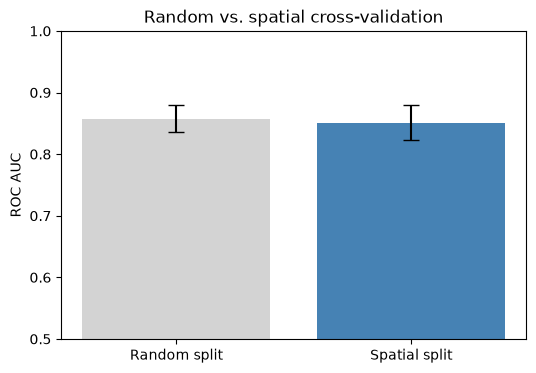

In [20]:
import os
os.makedirs("../figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Random split", "Spatial split"], [auc_r.mean(), auc_s.mean()],
       yerr=[auc_r.std(), auc_s.std()], capsize=6, color=["lightgrey", "steelblue"])
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("ROC AUC")
ax.set_title("Random vs. spatial cross-validation")
plt.savefig("../figures/cv_comparison.png", dpi=150, bbox_inches="tight")

Part 1: Is LightGBM even needed?

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression

def make_logit():
    return make_pipeline(
        SimpleImputer(strategy="median"),   # fill the 10 missing incomes
        FunctionTransformer(np.log1p),      # tame the skewed features
        StandardScaler(),                   # put features on the same scale
        LogisticRegression(max_iter=1000),
    )

oof_logit, auc_l, ap_l = evaluate(spatial_cv, groups=gdf["block"], make_model=make_logit)

comparison = pd.DataFrame(
    {"ROC AUC": [fmt(auc_l), fmt(auc_s)], "Avg precision": [fmt(ap_l), fmt(ap_s)]},
    index=["Logistic regression", "LightGBM"],
)
comparison

,ROC AUC,Avg precision
Logistic regression,0.894 ± 0.025,0.584 ± 0.126
LightGBM,0.851 ± 0.028,0.476 ± 0.120


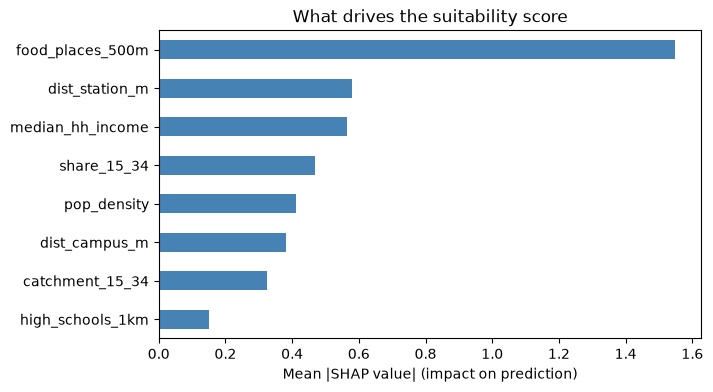

In [22]:
final_model = make_lgbm().fit(X, y)

contrib = final_model.predict(X, pred_contrib=True)
shap_df = pd.DataFrame(contrib[:, :-1], columns=FEATURES)   # last column is the baseline

importance = shap_df.abs().mean().sort_values()
ax = importance.plot.barh(figsize=(7, 4), color="steelblue")
ax.set_xlabel("Mean |SHAP value| (impact on prediction)")
ax.set_title("What drives the suitability score")
plt.savefig("../figures/shap_importance.png", dpi=150, bbox_inches="tight")

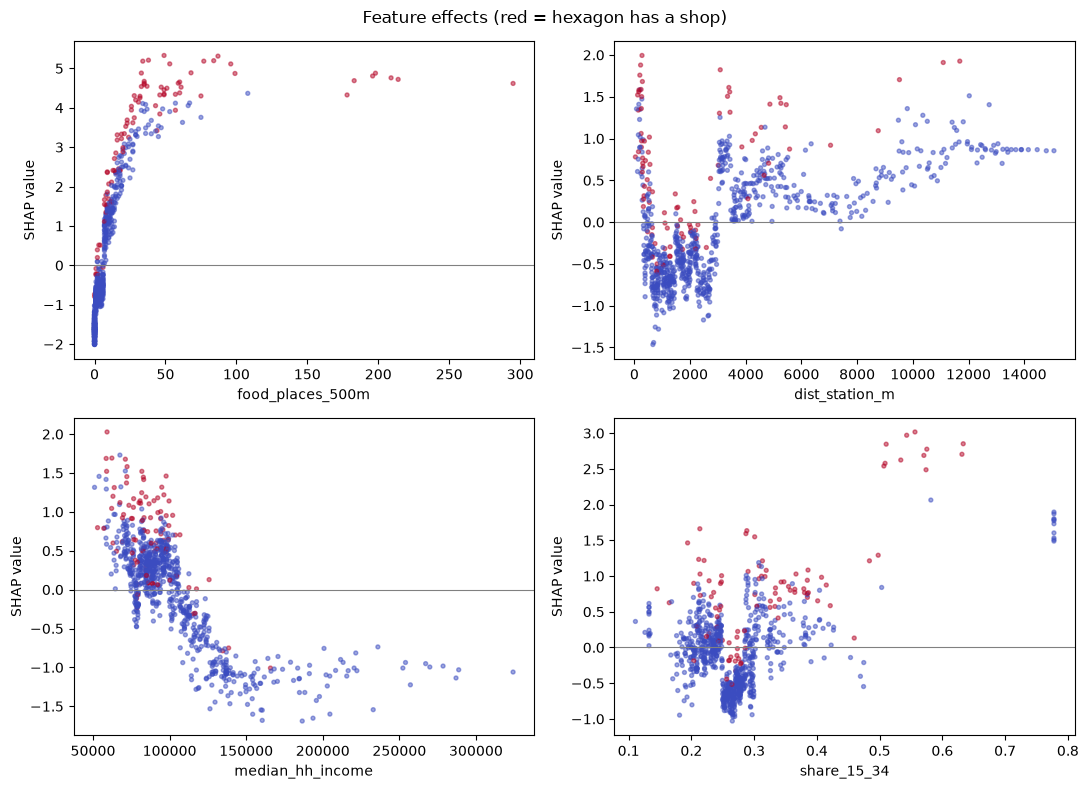

In [23]:
top4 = importance.index[::-1][:4]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.ravel(), top4):
    ax.scatter(X[feat], shap_df[feat], s=8, alpha=0.5, c=y, cmap="coolwarm")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xlabel(feat)
    ax.set_ylabel("SHAP value")
plt.suptitle("Feature effects (red = hexagon has a shop)")
plt.tight_layout()
plt.savefig("../figures/shap_dependence.png", dpi=150, bbox_inches="tight")

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import SplineTransformer

def make_rf():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                               class_weight="balanced", random_state=42, n_jobs=-1),
    )

# +1 = can only raise the score, -1 = can only lower it, 0 = no constraint
MONOTONE = {
    "dist_station_m": 0, "dist_campus_m": -1, "high_schools_1km": 1, "food_places_500m": 1,
    "catchment_15_34": 1, "median_hh_income": 0, "share_15_34": 0, "pop_density": 1,
}

def make_lgbm_reg():
    return LGBMClassifier(
        n_estimators=300, learning_rate=0.03, num_leaves=4, min_child_samples=30,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
        monotone_constraints=[MONOTONE[f] for f in FEATURES],
        random_state=42, verbose=-1,
    )

def make_spline_logit():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(np.log1p),
        SplineTransformer(n_knots=4, degree=3),
        LogisticRegression(C=0.5, max_iter=2000),
    )

models = {
    "Logistic regression": make_logit,
    "Logistic + splines": make_spline_logit,
    "Random forest": make_rf,
    "LightGBM": make_lgbm,
    "LightGBM regularized + monotone": make_lgbm_reg,
}

rows, oofs, fold_aucs = [], {}, {}
for name, make in models.items():
    oof, aucs, aps = evaluate(spatial_cv, groups=gdf["block"], make_model=make)
    oofs[name], fold_aucs[name] = oof, aucs
    rows.append({"Model": name, "ROC AUC": fmt(aucs), "Avg precision": fmt(aps),
                 "Folds beating logistic": int((aucs > auc_l).sum())})

pd.DataFrame(rows).set_index("Model")

,ROC AUC,Avg precision,Folds beating logistic
Model,,,
Logistic regression,0.894 ± 0.025,0.584 ± 0.126,0
Logistic + splines,0.887 ± 0.034,0.570 ± 0.116,2
Random forest,0.878 ± 0.025,0.514 ± 0.103,1
LightGBM,0.851 ± 0.028,0.476 ± 0.120,0
LightGBM regularized + monotone,0.878 ± 0.031,0.537 ± 0.129,1


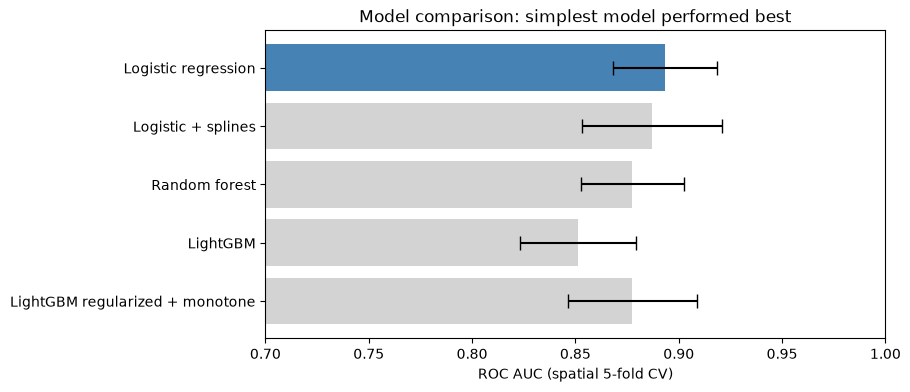

In [25]:
names = list(fold_aucs.keys())
means = [fold_aucs[n].mean() for n in names]
stds = [fold_aucs[n].std() for n in names]

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["steelblue" if n == "Logistic regression" else "lightgrey" for n in names]
ax.barh(names, means, xerr=stds, capsize=5, color=colors)
ax.set_xlim(0.7, 1.0)
ax.set_xlabel("ROC AUC (spatial 5-fold CV)")
ax.set_title("Model comparison: simplest model performed best")
ax.invert_yaxis()
plt.savefig("../figures/model_comparison.png", dpi=150, bbox_inches="tight")

In [26]:
pd.DataFrame({
    "LightGBM AUC": auc_s.round(3),
    "Logistic AUC": auc_l.round(3),
    "Logistic better": auc_l > auc_s,
}, index=[f"Fold {i+1}" for i in range(5)])

,LightGBM AUC,Logistic AUC,Logistic better
Fold 1,0.886,0.937,True
Fold 2,0.865,0.906,True
Fold 3,0.843,0.875,True
Fold 4,0.803,0.866,True
Fold 5,0.860,0.884,True


median_hh_income    0.69
high_schools_1km    0.98
dist_campus_m       0.99
pop_density         1.05
dist_station_m      1.08
catchment_15_34     1.08
share_15_34         1.22
food_places_500m    5.29
Name: Odds multiplier per 1 SD, dtype: float64

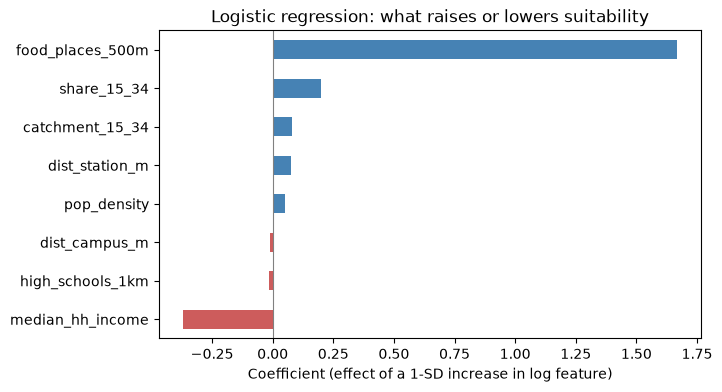

In [27]:
final_logit = make_logit().fit(X, y)
coefs = pd.Series(final_logit[-1].coef_[0], index=FEATURES).sort_values()

ax = coefs.plot.barh(figsize=(7, 4), color=["indianred" if c < 0 else "steelblue" for c in coefs])
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Coefficient (effect of a 1-SD increase in log feature)")
ax.set_title("Logistic regression: what raises or lowers suitability")
plt.savefig("../figures/logit_coefficients.png", dpi=150, bbox_inches="tight")

np.exp(coefs).round(2).rename("Odds multiplier per 1 SD")

## Isn’t the model just finding where restaurants are? Lets find out

In [28]:
FEATURES_NO_FOOD = [f for f in FEATURES if f != "food_places_500m"]

X_full = X                       # keep the full feature set safe
X = gdf[FEATURES_NO_FOOD]        # evaluate() uses X, so swap it temporarily
_, auc_nf, ap_nf = evaluate(spatial_cv, groups=gdf["block"], make_model=make_logit)
X = X_full                       # restore it right away

pd.DataFrame(
    {"ROC AUC": [fmt(auc_l), fmt(auc_nf)], "Avg precision": [fmt(ap_l), fmt(ap_nf)]},
    index=["All features", "Without food places"],
)

,ROC AUC,Avg precision
All features,0.894 ± 0.025,0.584 ± 0.126
Without food places,0.773 ± 0.070,0.428 ± 0.169


In [29]:
gdf["suitability"] = oof_logit   # spatial out-of-fold scores from logistic regression
gdf.to_file("../data/processed/scored_hexes.gpkg", driver="GPKG")
print("Saved scores for", len(gdf), "hexagons")

Saved scores for 846 hexagons
